In [1]:

import pandas as pd

# Load the training and testing datasets
train_df = pd.read_csv("churn-bigml-80.csv")
test_df = pd.read_csv("churn-bigml-20.csv")

# Check dataset dimensions
print("Training dataset shape:", train_df.shape)
print("Testing dataset shape:", test_df.shape)

# Display the first five rows
display(train_df.head())


Training dataset shape: (2666, 20)
Testing dataset shape: (667, 20)


,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
0,KS,128,415,No,Yes,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,No,Yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,No,No,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,Yes,No,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,Yes,No,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


In [2]:

# Inspect column names and data types
train_df.info()

# Check missing values
print("\nMissing values:")
print(train_df.isnull().sum().sum())

# Check target distribution
print("\nChurn distribution:")
print(train_df["Churn"].value_counts())

print("\nChurn percentages:")
print(
    (train_df["Churn"].value_counts(normalize=True) * 100).round(2)
)


<class 'pandas.DataFrame'>
RangeIndex: 2666 entries, 0 to 2665
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   State                   2666 non-null   str    
 1   Account length          2666 non-null   int64  
 2   Area code               2666 non-null   int64  
 3   International plan      2666 non-null   str    
 4   Voice mail plan         2666 non-null   str    
 5   Number vmail messages   2666 non-null   int64  
 6   Total day minutes       2666 non-null   float64
 7   Total day calls         2666 non-null   int64  
 8   Total day charge        2666 non-null   float64
 9   Total eve minutes       2666 non-null   float64
 10  Total eve calls         2666 non-null   int64  
 11  Total eve charge        2666 non-null   float64
 12  Total night minutes     2666 non-null   float64
 13  Total night calls       2666 non-null   int64  
 14  Total night charge      2666 non-null   float64
 15

In [3]:

# Separate input features from the target
X_train = train_df.drop("Churn", axis=1)
y_train = train_df["Churn"]

X_test = test_df.drop("Churn", axis=1)
y_test = test_df["Churn"]

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

print("\nTraining target classes:")
print(y_train.value_counts())


X_train shape: (2666, 19)
y_train shape: (2666,)
X_test shape: (667, 19)
y_test shape: (667,)

Training target classes:
Churn
False    2278
True      388
Name: count, dtype: int64


In [4]:

# Identify numerical and categorical features
numerical_cols = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_cols = X_train.select_dtypes(
    include=["str", "object", "category", "bool"]
).columns.tolist()

print("Numerical columns:", numerical_cols)
print("\nCategorical columns:", categorical_cols)


Numerical columns: ['Account length', 'Area code', 'Number vmail messages', 'Total day minutes', 'Total day calls', 'Total day charge', 'Total eve minutes', 'Total eve calls', 'Total eve charge', 'Total night minutes', 'Total night calls', 'Total night charge', 'Total intl minutes', 'Total intl calls', 'Total intl charge', 'Customer service calls']

Categorical columns: ['State', 'International plan', 'Voice mail plan']


In [5]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
    ]
)

print("Preprocessing pipeline created successfully!")


Preprocessing pipeline created successfully!


In [6]:

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)


Processed training shape: (2666, 71)
Processed testing shape: (667, 71)


In [7]:

from sklearn.linear_model import LogisticRegression

# Create the logistic regression model
model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

# Train the model
model.fit(X_train_processed, y_train)

print("Logistic Regression model trained successfully!")


Logistic Regression model trained successfully!


In [8]:

# Predict whether each test customer will churn
y_pred = model.predict(X_test_processed)

# Get predicted probabilities for churn
y_prob = model.predict_proba(X_test_processed)[:, 1]

print("First 10 actual values:")
print(y_test.iloc[:10].tolist())

print("\nFirst 10 predicted values:")
print(y_pred[:10].tolist())

print("\nFirst 10 churn probabilities:")
print(y_prob[:10].round(3).tolist())


First 10 actual values:
[False, True, True, False, False, False, False, True, False, False]

First 10 predicted values:
[False, True, True, False, False, False, True, True, False, False]

First 10 churn probabilities:
[0.465, 0.557, 0.952, 0.289, 0.063, 0.025, 0.696, 0.709, 0.217, 0.37]


In [9]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_prob)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))


Accuracy:  0.7796
Precision: 0.3687
Recall:    0.7684
F1-score:  0.4983
ROC-AUC:   0.8184

Confusion Matrix:
[[447 125]
 [ 22  73]]

Classification Report:
              precision    recall  f1-score   support

       False       0.95      0.78      0.86       572
        True       0.37      0.77      0.50        95

    accuracy                           0.78       667
   macro avg       0.66      0.77      0.68       667
weighted avg       0.87      0.78      0.81       667



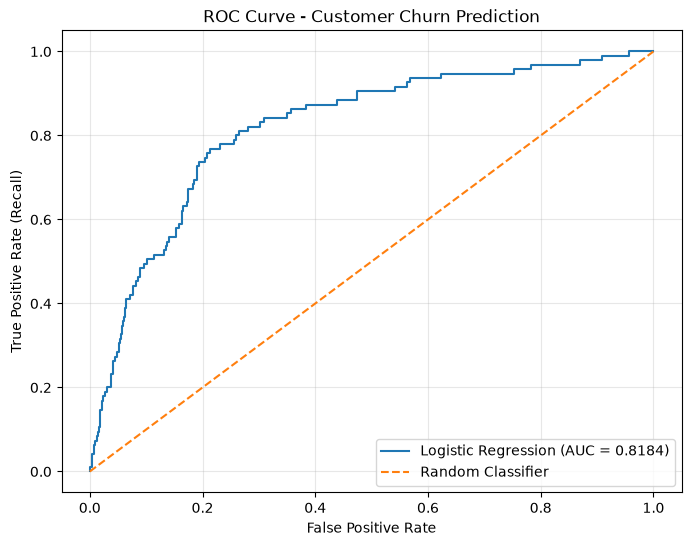

In [10]:

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Calculate ROC curve values
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# Calculate ROC-AUC
roc_auc = roc_auc_score(y_test, y_prob)

# Plot the curve
plt.figure(figsize=(8, 6))
plt.plot(
    fpr, tpr,
    label=f"Logistic Regression (AUC = {roc_auc:.4f})"
)
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve - Customer Churn Prediction")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()


In [11]:

import numpy as np

# Get the feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# Extract model coefficients
coefficients = model.coef_[0]

# Create a table of coefficients and odds ratios
coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Odds Ratio": np.exp(coefficients)
})

# Sort by the largest positive coefficients
coef_df = coef_df.sort_values(
    by="Coefficient",
    ascending=False
)

print("Top 10 features associated with higher churn odds:")
print(coef_df.head(10).to_string(index=False))

print("\nTop 10 features associated with lower churn odds:")
print(
    coef_df.tail(10)
    .sort_values(by="Coefficient")
    .to_string(index=False)
)


Top 10 features associated with higher churn odds:
                    Feature  Coefficient  Odds Ratio
cat__International plan_Yes     1.219735    3.386292
              cat__State_SC     1.076560    2.934568
              cat__State_MS     1.006914    2.737140
              cat__State_TX     0.964010    2.622190
              cat__State_MT     0.961063    2.614473
    cat__Voice mail plan_No     0.934937    2.547052
              cat__State_CA     0.821110    2.273021
num__Customer service calls     0.791496    2.206694
              cat__State_NJ     0.666713    1.947824
              cat__State_ME     0.635196    1.887391

Top 10 features associated with lower churn odds:
                   Feature  Coefficient  Odds Ratio
             cat__State_RI    -1.565319    0.209021
cat__International plan_No    -1.273559    0.279834
             cat__State_HI    -1.250891    0.286250
             cat__State_VA    -1.059881    0.346497
  cat__Voice mail plan_Yes    -0.988761    0.372038
   

In [12]:

# Save the complete coefficient and odds-ratio table
coef_df.to_csv(
    "logistic_regression_coefficients.csv",
    index=False
)

print("Coefficient analysis saved successfully!")


Coefficient analysis saved successfully!


In [13]:

import joblib

joblib.dump(
    {
        "model": model,
        "preprocessor": preprocessor
    },
    "churn_logistic_regression.pkl"
)

print("Model and preprocessor saved successfully!")


Model and preprocessor saved successfully!
